In [1]:
%pip install pandas sqlalchemy mysql-connector-python matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

In [2]:
password = getpass("MySQL password enter karo: ")

connection_url = URL.create(
    drivername="mysql+mysqlconnector",
    username="root",
    password=password,
    host="localhost",
    port=3306,
    database="e_commerce_business_intelligence_platform_v4"
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    database = connection.execute(
        text("SELECT DATABASE()")
    ).scalar()

print("Connected to:", database)

MySQL password enter karo:  ········


Connected to: e_commerce_business_intelligence_platform_v4


In [3]:
with engine.connect() as connection:
    sales = pd.read_sql_query(
        text("SELECT * FROM sales"), connection
    )

    customers = pd.read_sql_query(
        text("SELECT * FROM customers"), connection
    )

    products = pd.read_sql_query(
        text("SELECT * FROM products"), connection
    )

    profit = pd.read_sql_query(
        text("SELECT * FROM profitability"), connection
    )

print("Sales:", sales.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Profitability:", profit.shape)

Sales: (2000, 19)
Customers: (2000, 14)
Products: (2000, 13)
Profitability: (2000, 19)


In [4]:
display(sales.head())

print("Sales table mein missing values:")
print(sales.isna().sum())

,Order_ID,Order_Date,Customer_ID,Customer_Segment,City,State,Product_ID,Product_Name,Category,Subcategory,Quantity,Unit_Price,Gross_Sales,Discount_Pct,Discount_Amount,Net_Sales,Payment_Method,Sales_Channel,Order_Status
0,ORD100001,2025-03-04,C0491,Consumer,Chennai,Tamil Nadu,P1030,Kitchen Appliances Product 5,Home & Kitchen,Kitchen Appliances,5,2323.15,11615.75,25,2903.94,8711.81,Net Banking,Mobile App,Delivered
1,ORD100002,2024-05-18,C0337,Consumer,Mumbai,Maharashtra,P1086,Outdoor Product 1,Sports,Outdoor,4,14175.84,56703.36,15,8505.50,48197.86,Debit Card,Marketplace,Delivered
2,ORD100003,2025-11-23,C0446,Consumer,Lucknow,Uttar Pradesh,P1092,Sportswear Product 2,Sports,Sportswear,5,32635.01,163175.05,15,24476.26,138698.79,UPI,Marketplace,Delivered
3,ORD100004,2025-06-25,C0365,Home Office,Kolkata,West Bengal,P1007,Laptops Product 2,Electronics,Laptops,5,2751.82,13759.10,15,2063.86,11695.24,Credit Card,Website,Delivered
4,ORD100005,2024-02-26,C0491,Consumer,Chennai,Tamil Nadu,P1035,Home Decor Product 5,Home & Kitchen,Home Decor,5,41822.61,209113.05,20,41822.61,167290.44,Credit Card,Website,Delivered


Sales table mein missing values:
Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Segment    0
City                0
State               0
Product_ID          0
Product_Name        0
Category            0
Subcategory         0
Quantity            0
Unit_Price          0
Gross_Sales         0
Discount_Pct        0
Discount_Amount     0
Net_Sales           0
Payment_Method      0
Sales_Channel       0
Order_Status        0
dtype: int64


In [5]:
tables = {
    "Sales": sales,
    "Customers": customers,
    "Products": products,
    "Profitability": profit
}

for name, df in tables.items():
    print(name)
    print("Total rows:", len(df))
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())
    print("-" * 35)

Sales
Total rows: 2000
Missing values: 0
Duplicate rows: 0
Duplicate Order IDs: 0
-----------------------------------
Customers
Total rows: 2000
Missing values: 0
Duplicate rows: 0
Duplicate Order IDs: 0
-----------------------------------
Products
Total rows: 2000
Missing values: 0
Duplicate rows: 0
Duplicate Order IDs: 0
-----------------------------------
Profitability
Total rows: 2000
Missing values: 0
Duplicate rows: 0
Duplicate Order IDs: 0
-----------------------------------


In [6]:
for name, df in tables.items():
    # Column names ke extra spaces remove karna
    df.columns = df.columns.str.strip()

    # Text values ke aage-peeche ke spaces remove karna
    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for column in text_columns:
        if column != "Order_Date":
            df[column] = df[column].map(
                lambda value: value.strip()
                if isinstance(value, str)
                else value
            )

    # Date column ko datetime format mein convert karna
    df["Order_Date"] = pd.to_datetime(
        df["Order_Date"],
        errors="raise"
    )

print("Text aur dates ki cleaning complete!")

Text aur dates ki cleaning complete!


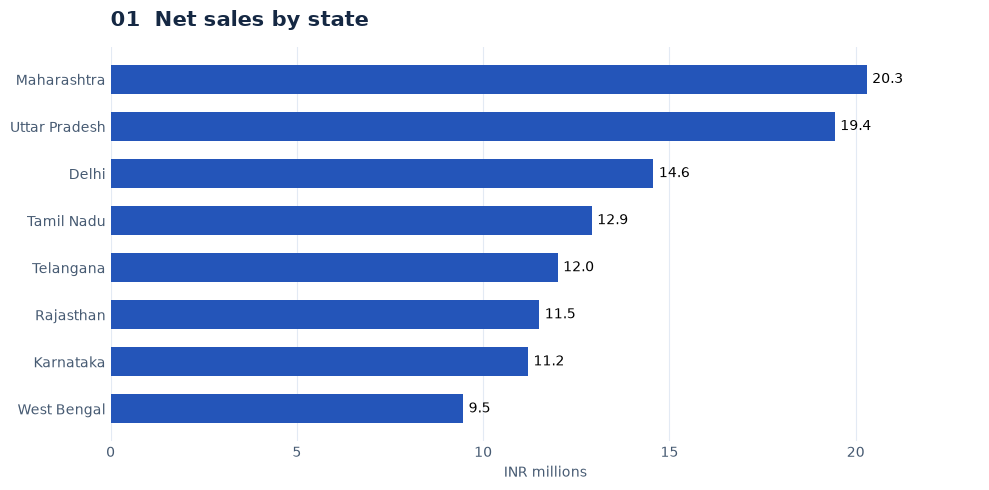

In [7]:
import matplotlib.pyplot as plt

# Har state ki total sales calculate karna
state_sales = (
    sales.groupby("State")["Net_Sales"]
    .sum()
    .sort_values()
)

# Sales ko millions mein convert karna
state_sales_million = state_sales / 1_000_000

# Chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    state_sales_million.index,
    state_sales_million.values,
    color="#2455b9",
    height=0.62
)

# Har bar ke saamne sales value dikhana
for position, value in enumerate(state_sales_million):
    ax.text(
        value + 0.15,
        position,
        f"{value:.1f}",
        va="center",
        fontsize=10
    )

# Title aur axis label
ax.set_title(
    "01  Net sales by state",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("INR millions", color="#465a72")

# Grid aur borders ki formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")

for spine in ax.spines.values():
    spine.set_visible(False)

# Values ke liye right side mein jagah
ax.set_xlim(0, state_sales_million.max() * 1.15)

plt.tight_layout()
plt.show()

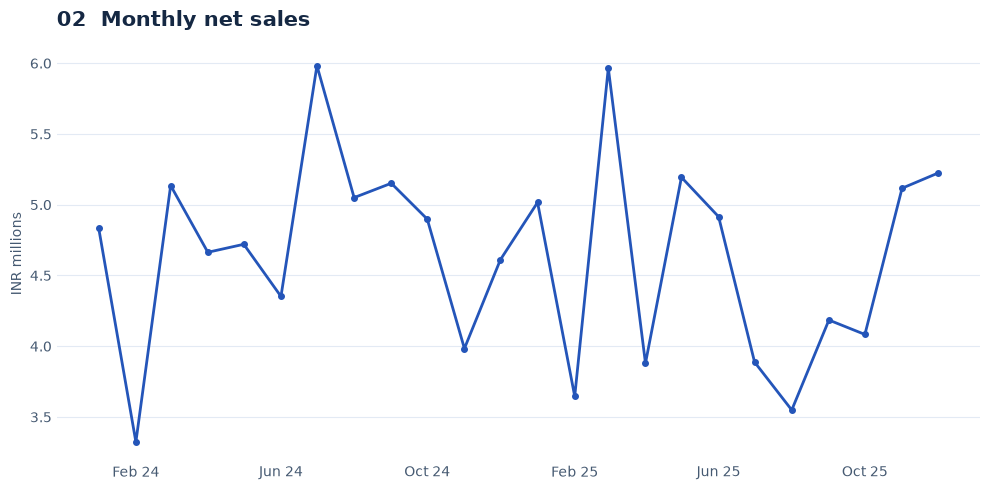

In [8]:
import matplotlib.dates as mdates

# Year aur month ke according total sales
monthly_sales = (
    sales.groupby(sales["Order_Date"].dt.to_period("M"))["Net_Sales"]
    .sum()
    .sort_index()
)

# Months ko plotting ke liye dates mein convert karna
months = monthly_sales.index.to_timestamp()

# Sales ko millions mein convert karna
monthly_sales_million = monthly_sales / 1_000_000

# Line chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    months,
    monthly_sales_million,
    color="#2455b9",
    linewidth=2,
    marker="o",
    markersize=4
)

ax.set_title(
    "02  Monthly net sales",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_ylabel("INR millions", color="#465a72")

# Date labels ko reference jaisa dikhana
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=4)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %y")
)

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="y", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

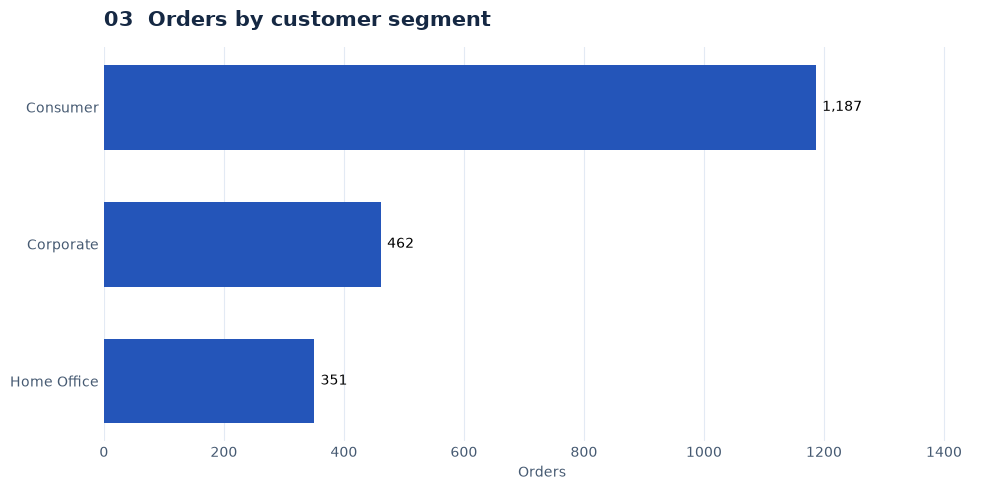

In [9]:
# Har customer segment ke unique orders count karna
segment_orders = (
    customers.groupby("Customer_Segment")["Order_ID"]
    .nunique()
    .sort_values()
)

# Horizontal bar chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    segment_orders.index,
    segment_orders.values,
    color="#2455b9",
    height=0.62
)

# Bars ke saamne order counts dikhana
for position, value in enumerate(segment_orders):
    ax.text(
        value + 10,
        position,
        f"{value:,}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "03  Orders by customer segment",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("Orders", color="#465a72")

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")
ax.set_xlim(0, segment_orders.max() * 1.23)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

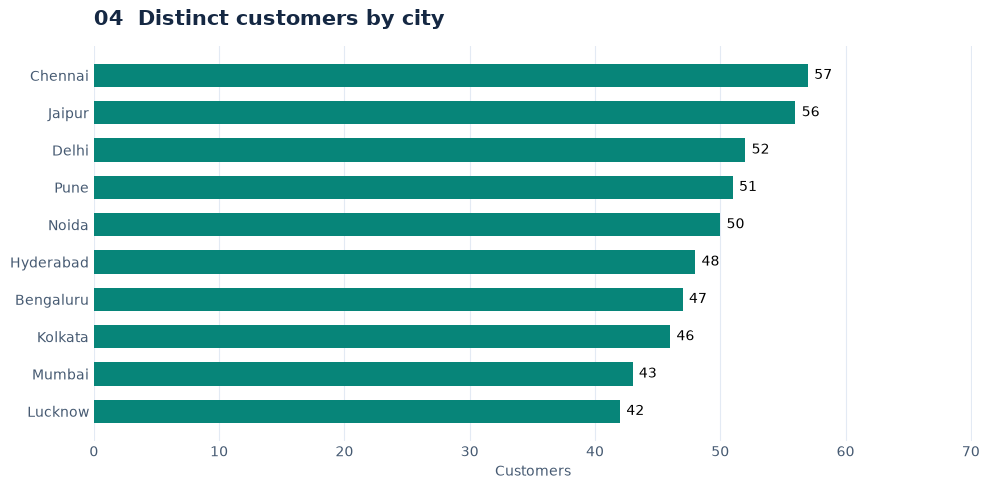

In [10]:
# Har city ke unique customers count karna
city_customers = (
    customers.groupby("City")["Customer_ID"]
    .nunique()
    .sort_values()
)

# Horizontal bar chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    city_customers.index,
    city_customers.values,
    color="#078579",
    height=0.62
)

# Har bar ke saamne customer count
for position, value in enumerate(city_customers):
    ax.text(
        value + 0.5,
        position,
        f"{value:,}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "04  Distinct customers by city",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("Customers", color="#465a72")

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")
ax.set_xlim(0, city_customers.max() * 1.23)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

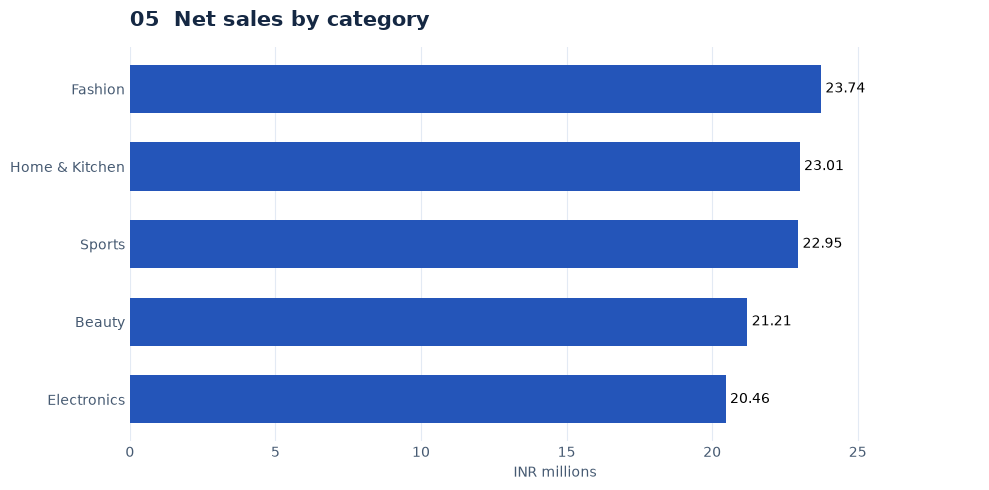

In [11]:
# Har product category ki total sales
category_sales = (
    products.groupby("Category")["Net_Sales"]
    .sum()
    .sort_values()
)

# Sales ko millions mein convert karna
category_sales_million = category_sales / 1_000_000

# Horizontal bar chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    category_sales_million.index,
    category_sales_million.values,
    color="#2455b9",
    height=0.62
)

# Har bar ke saamne sales value
for position, value in enumerate(category_sales_million):
    ax.text(
        value + 0.15,
        position,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "05  Net sales by category",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("INR millions", color="#465a72")

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")
ax.set_xlim(0, category_sales_million.max() * 1.23)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

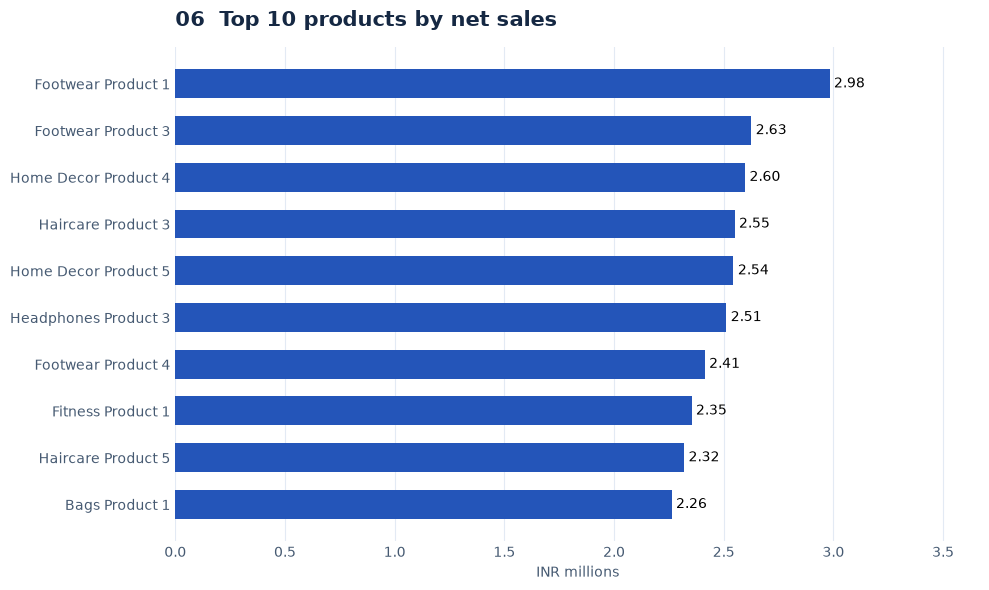

In [12]:
# Total sales ke according top 10 products select karna
top_products = (
    products.groupby("Product_Name")["Net_Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

# Sales ko millions mein convert karna
top_products_million = top_products / 1_000_000

# Horizontal bar chart banana
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_products_million.index,
    top_products_million.values,
    color="#2455b9",
    height=0.62
)

# Har bar ke saamne sales value
for position, value in enumerate(top_products_million):
    ax.text(
        value + 0.02,
        position,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "06  Top 10 products by net sales",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("INR millions", color="#465a72")

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")
ax.set_xlim(0, top_products_million.max() * 1.23)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

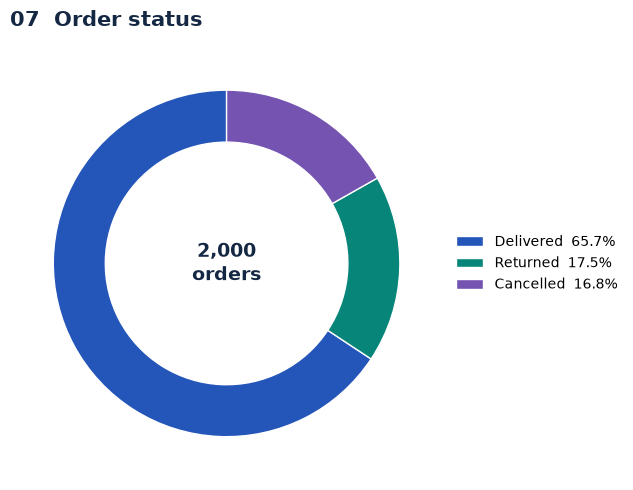

In [13]:
# Status-wise orders count karna
status_orders = (
    sales.groupby("Order_Status")["Order_ID"]
    .nunique()
    .reindex(["Delivered", "Returned", "Cancelled"], fill_value=0)
)

total_orders = status_orders.sum()

# Donut chart banana
fig, ax = plt.subplots(figsize=(8, 5))

wedges, _ = ax.pie(
    status_orders.values,
    colors=["#2455b9", "#078579", "#7453b1"],
    startangle=90,
    wedgeprops={
        "width": 0.3,
        "edgecolor": "white"
    }
)

# Donut ke centre mein total orders
ax.text(
    0, 0,
    f"{total_orders:,}\norders",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    color="#152843"
)

# Legend mein status aur percentage
legend_labels = [
    f"{status}  {count / total_orders:.1%}"
    for status, count in status_orders.items()
]

ax.legend(
    wedges,
    legend_labels,
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.set_title(
    "07  Order status",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_aspect("equal")

plt.tight_layout()
plt.show()

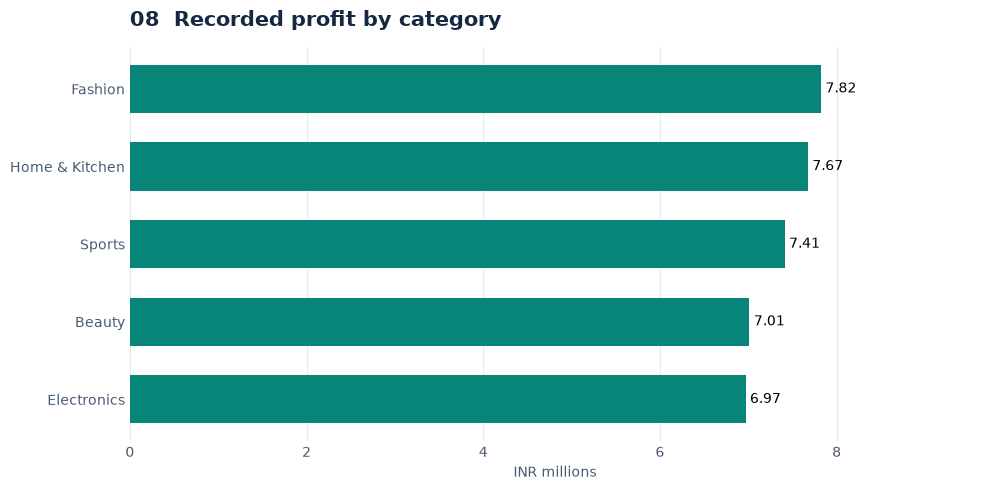

In [14]:
# Har category ka total recorded profit
category_profit = (
    profit.groupby("Category")["Profit"]
    .sum()
    .sort_values()
)

# Profit ko millions mein convert karna
category_profit_million = category_profit / 1_000_000

# Horizontal bar chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    category_profit_million.index,
    category_profit_million.values,
    color="#078579",
    height=0.62
)

# Har bar ke saamne profit value
for position, value in enumerate(category_profit_million):
    ax.text(
        value + 0.05,
        position,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "08  Recorded profit by category",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("INR millions", color="#465a72")

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")
ax.set_xlim(0, category_profit_million.max() * 1.23)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

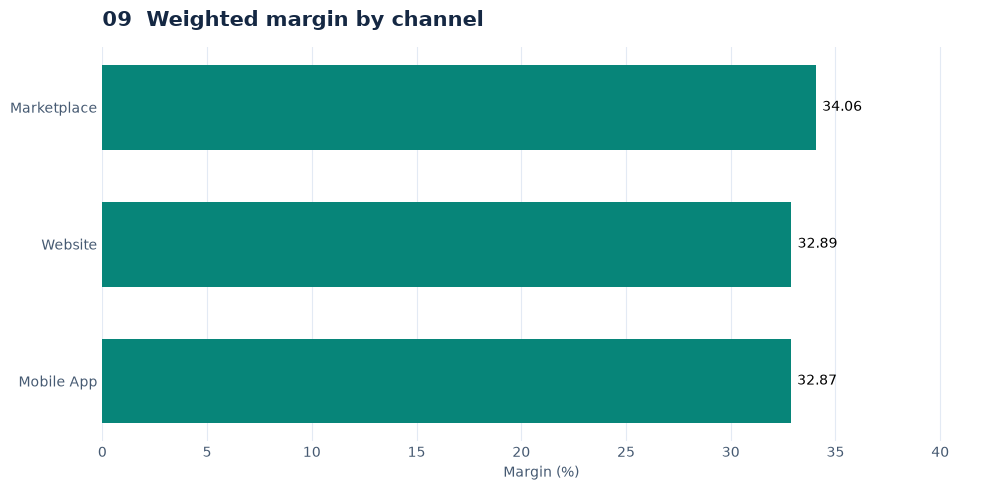

In [15]:
# Har sales channel ki total sales aur profit
channel_totals = (
    profit.groupby("Sales_Channel")[["Profit", "Net_Sales"]]
    .sum()
)

# Weighted profit margin calculate karna
channel_margin = (
    channel_totals["Profit"]
    / channel_totals["Net_Sales"]
    * 100
).sort_values()

# Horizontal bar chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    channel_margin.index,
    channel_margin.values,
    color="#078579",
    height=0.62
)

# Har bar ke saamne margin value
for position, value in enumerate(channel_margin):
    ax.text(
        value + 0.3,
        position,
        f"{value:.2f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "09  Weighted margin by channel",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("Margin (%)", color="#465a72")

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="x", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")
ax.set_xlim(0, channel_margin.max() * 1.23)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

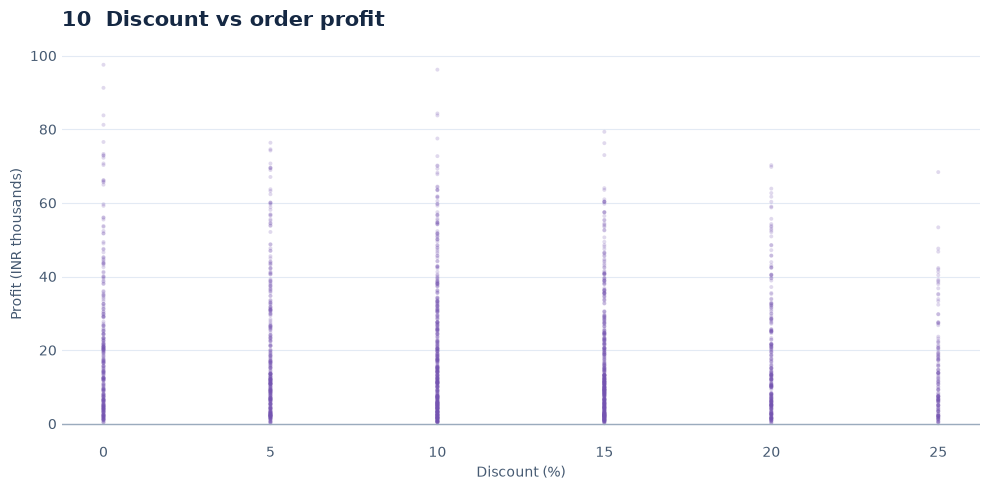

In [16]:
# Scatter plot banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    profit["Discount_Pct"],
    profit["Profit"] / 1000,
    color="#7453b1",
    s=8,
    alpha=0.22,
    edgecolors="none"
)

ax.set_title(
    "10  Discount vs order profit",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_xlabel("Discount (%)", color="#465a72")
ax.set_ylabel("Profit (INR thousands)", color="#465a72")

# Zero profit ki reference line
ax.axhline(
    0,
    color="#9babbd",
    linewidth=1
)

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="y", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

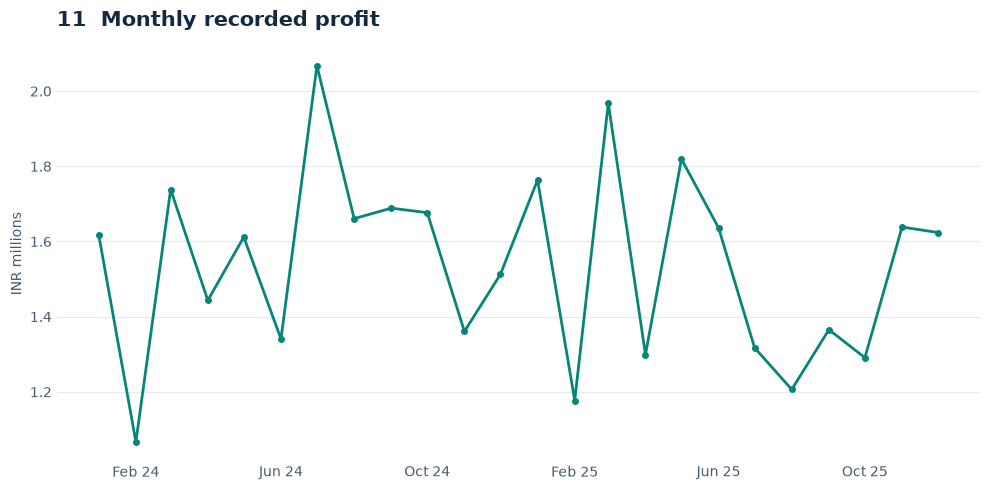

In [17]:
import matplotlib.dates as mdates

# Har year-month ka total profit calculate karna
monthly_profit = (
    profit.groupby(profit["Order_Date"].dt.to_period("M"))["Profit"]
    .sum()
    .sort_index()
)

# Months ko dates mein aur profit ko millions mein convert karna
months = monthly_profit.index.to_timestamp()
monthly_profit_million = monthly_profit / 1_000_000

# Line chart banana
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    months,
    monthly_profit_million,
    color="#078579",
    linewidth=2,
    marker="o",
    markersize=4
)

ax.set_title(
    "11  Monthly recorded profit",
    loc="left",
    fontsize=15,
    fontweight="bold",
    color="#152843",
    pad=15
)

ax.set_ylabel("INR millions", color="#465a72")

# X-axis par month aur year dikhana
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=4)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %y")
)

# Chart formatting
ax.set_axisbelow(True)
ax.grid(axis="y", color="#e3eaf4")
ax.tick_params(length=0, colors="#465a72")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

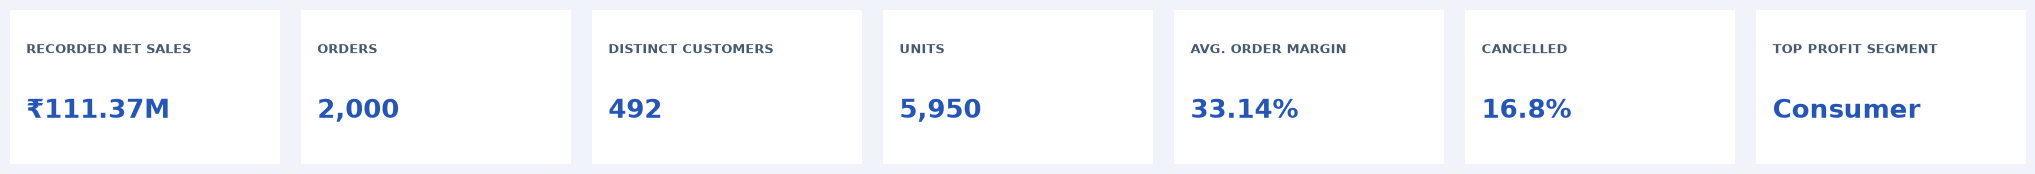

In [18]:
# 1. KPI values calculate karna
total_sales = sales["Net_Sales"].sum()
total_orders = sales["Order_ID"].nunique()
total_customers = customers["Customer_ID"].nunique()
total_units = sales["Quantity"].sum()

# Har order ka margin calculate karke average lena
average_margin = (
    profit["Profit"]
    / profit["Net_Sales"].where(profit["Net_Sales"] != 0)
    * 100
).mean()

cancelled_orders = sales.loc[
    sales["Order_Status"] == "Cancelled",
    "Order_ID"
].nunique()

cancellation_rate = cancelled_orders / total_orders * 100

# Sabse zyada total profit wala customer segment
segment_profit = (
    profit.groupby("Customer_Segment")["Profit"].sum()
)

top_segment = segment_profit.idxmax()

# 2. Cards ke labels aur values
cards = [
    ("RECORDED NET SALES", f"₹{total_sales / 1_000_000:,.2f}M"),
    ("ORDERS", f"{total_orders:,}"),
    ("DISTINCT CUSTOMERS", f"{total_customers:,}"),
    ("UNITS", f"{total_units:,}"),
    ("AVG. ORDER MARGIN", f"{average_margin:.2f}%"),
    ("CANCELLED", f"{cancellation_rate:.1f}%"),
    ("TOP PROFIT SEGMENT", top_segment)
]

# 3. Ek row mein 7 cards banana
fig, card_axes = plt.subplots(
    1, 7,
    figsize=(21, 2.2),
    facecolor="#f0f4fa"
)

for ax, (label, value) in zip(card_axes, cards):
    ax.set_facecolor("white")

    ax.text(
        0.06, 0.72,
        label,
        transform=ax.transAxes,
        fontsize=9,
        fontweight="bold",
        color="#465a72"
    )

    ax.text(
        0.06, 0.30,
        value,
        transform=ax.transAxes,
        fontsize=19,
        fontweight="bold",
        color="#2455b9"
    )

    # Axis ticks aur borders hatana
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.85,
    bottom=0.15,
    wspace=0.08
)

plt.show()

In [22]:
dashboard.text(
    0.04, 0.966,
    "E-Commerce Business Intelligence Platform",
    fontsize=30,
    fontweight="bold",
    color="white",
    va="center"
)

Text(0.04, 0.966, 'E-Commerce Business Intelligence Platform')

In [ ]:
dashboard.text(
    0.04, 0.966,
    "E-Commerce Business Intelligence Platform",
    fontsize=30,
    fontweight="bold",
    color="white",
    va="center"
)

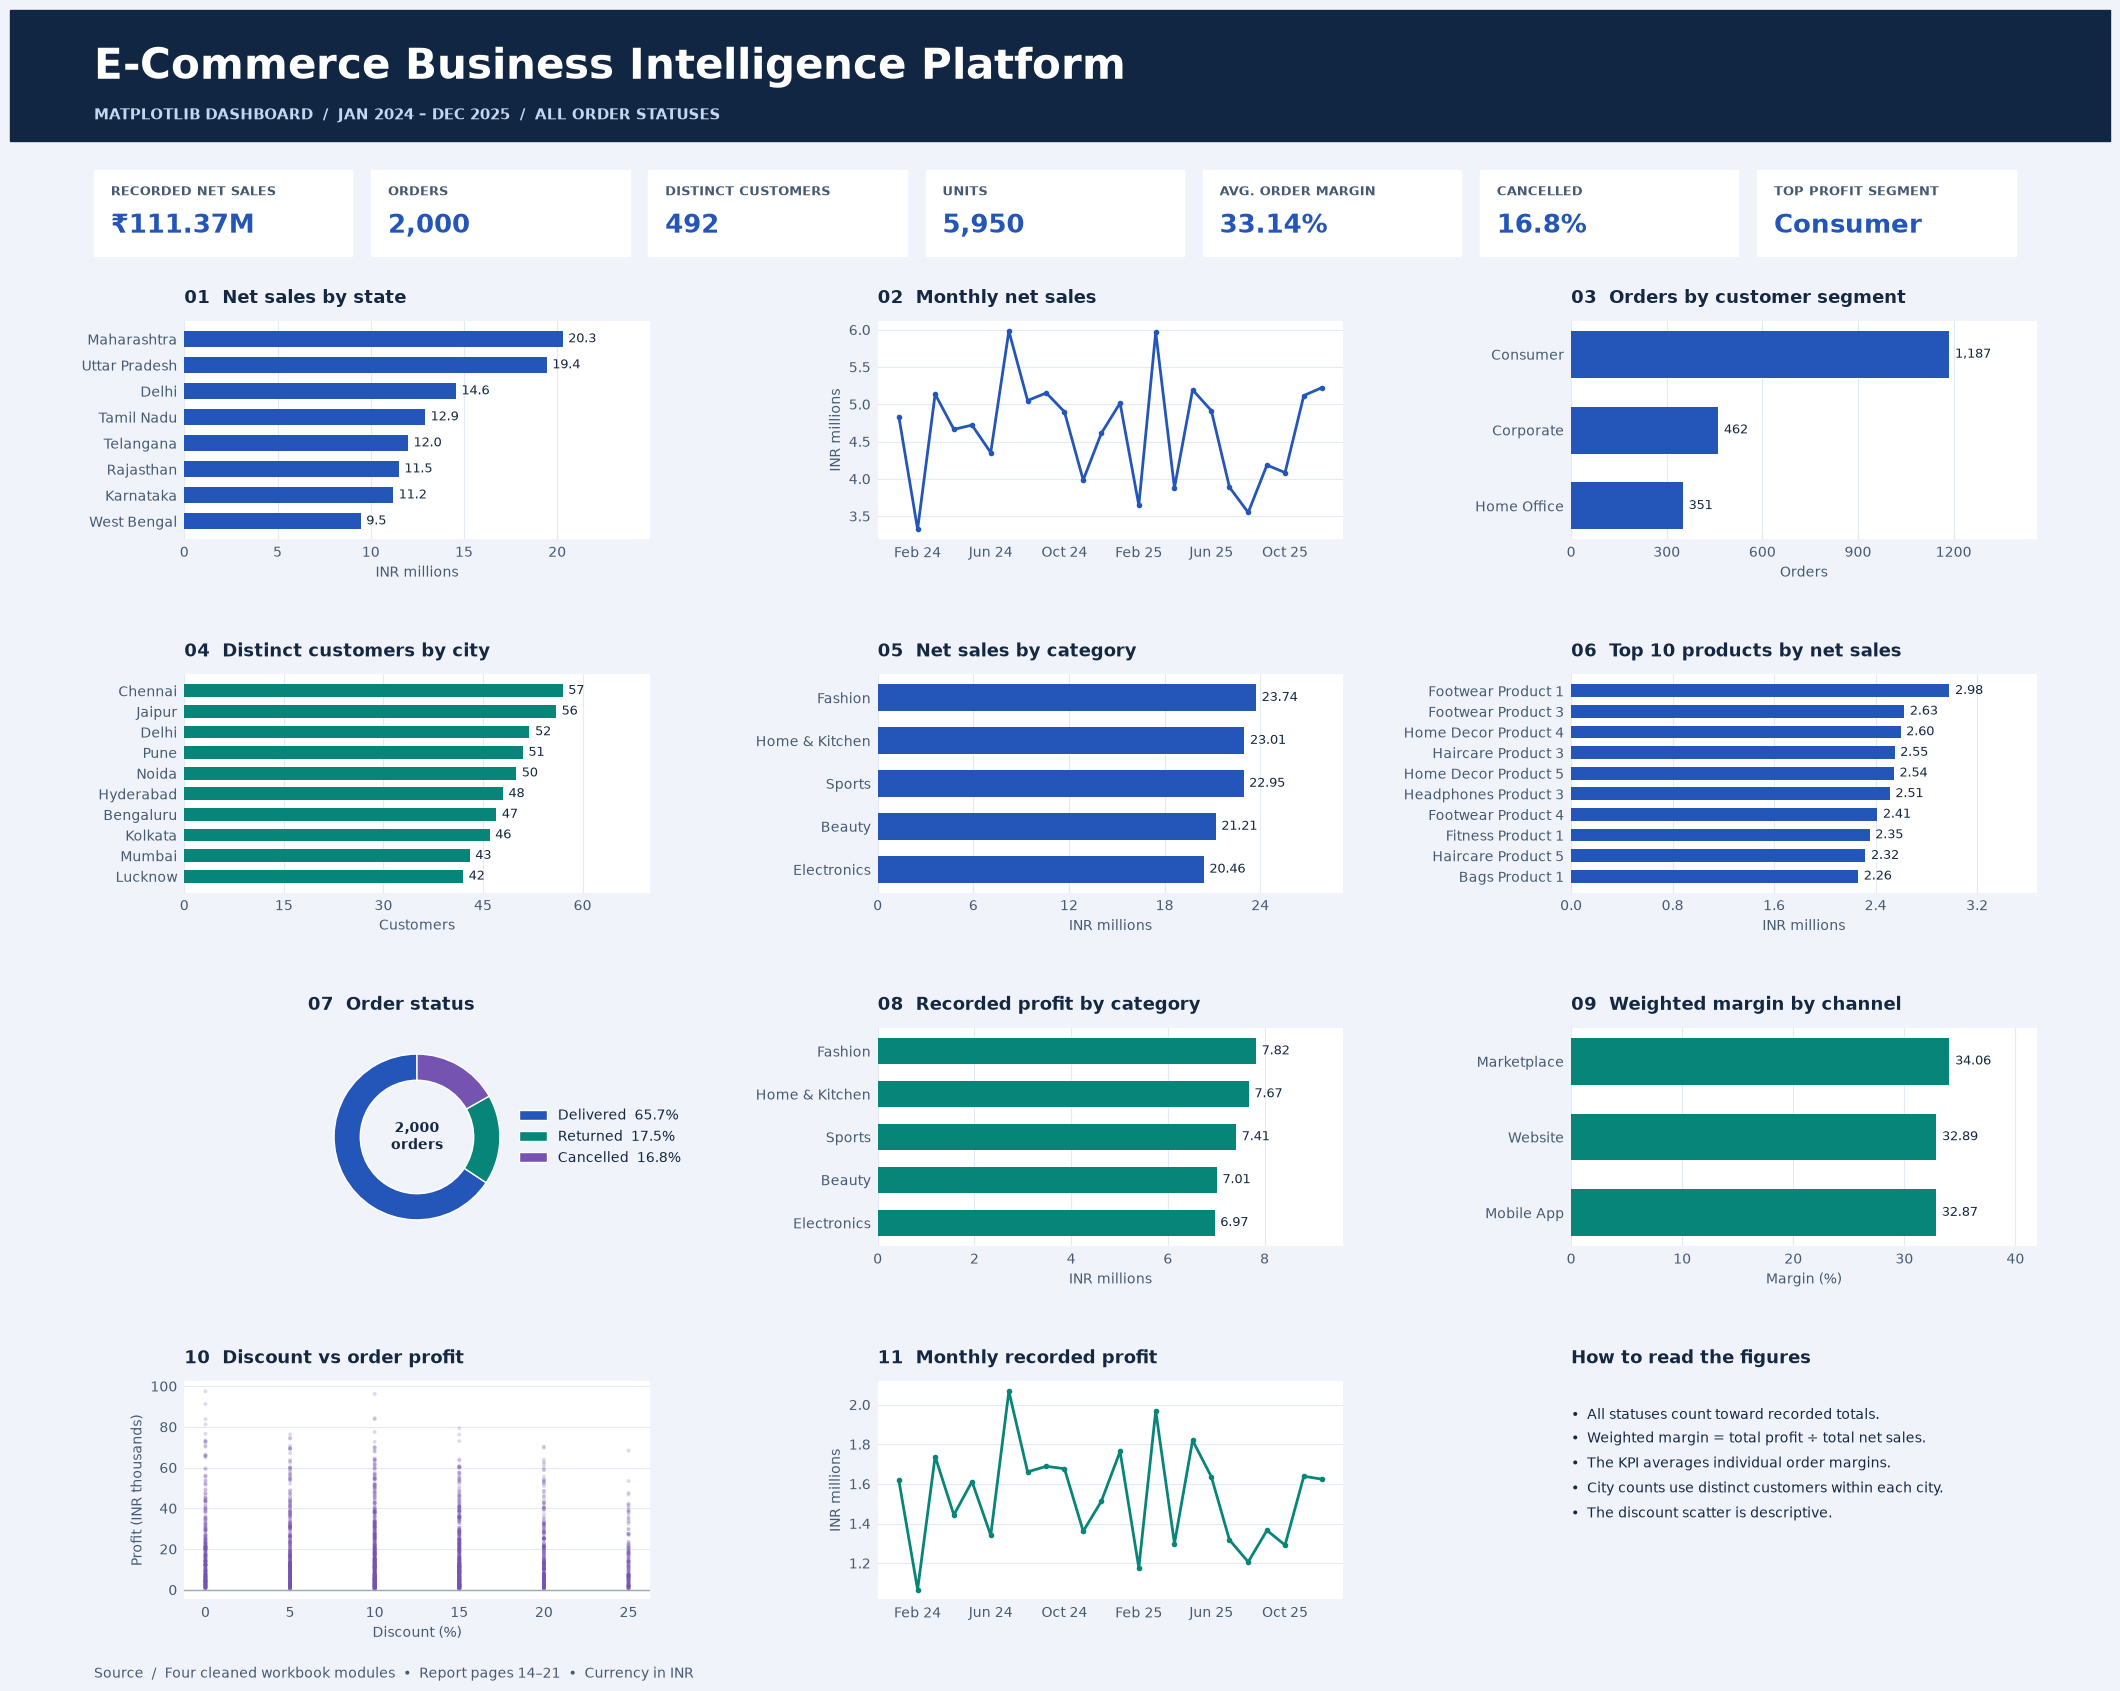

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

# ---------- Dashboard theme ----------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": "#152843",
    "axes.labelcolor": "#465a72",
    "xtick.color": "#465a72",
    "ytick.color": "#465a72"
})

blue = "#2455b9"
teal = "#078579"
purple = "#7453b1"

# ---------- 4 rows × 3 columns ----------

dashboard, axes = plt.subplots(
    4, 3,
    figsize=(21, 17),
    facecolor="#f0f4fa"
)

dashboard.subplots_adjust(
    left=0.083,
    right=0.965,
    bottom=0.065,
    top=0.817,
    hspace=0.62,
    wspace=0.49
)

# ---------- Title ----------

dashboard.add_artist(
    plt.Rectangle(
        (0, 0.923), 1, 0.077,
        transform=dashboard.transFigure,
        color="#102642"
    )
)

dashboard.text(
    0.04, 0.966,
    "E-Commerce Business Intelligence Platform",
    fontsize=30,
    fontweight="bold",
    color="white",
    va="center"
)

start_date = pd.to_datetime(sales["Order_Date"]).min()
end_date = pd.to_datetime(sales["Order_Date"]).max()

period = f"{start_date:%b %Y} – {end_date:%b %Y}".upper()

dashboard.text(
    0.04, 0.938,
    f"MATPLOTLIB DASHBOARD  /  {period}  /  ALL ORDER STATUSES",
    fontsize=11,
    fontweight="bold",
    color="#c5d7f0",
    va="center"
)

# ---------- KPI cards ----------

total_orders = sales["Order_ID"].nunique()

average_margin = (
    100 * profit["Profit"]
    / profit["Net_Sales"].where(profit["Net_Sales"] != 0)
).mean()

status_orders = (
    sales.groupby("Order_Status")["Order_ID"]
    .nunique()
    .reindex(["Delivered", "Returned", "Cancelled"], fill_value=0)
)

segment_profit = (
    profit.groupby("Customer_Segment")["Profit"].sum()
)

cards = [
    (
        "RECORDED NET SALES",
        f"₹{sales['Net_Sales'].sum() / 1e6:,.2f}M"
    ),
    ("ORDERS", f"{total_orders:,}"),
    (
        "DISTINCT CUSTOMERS",
        f"{customers['Customer_ID'].nunique():,}"
    ),
    ("UNITS", f"{sales['Quantity'].sum():,}"),
    ("AVG. ORDER MARGIN", f"{average_margin:.2f}%"),
    (
        "CANCELLED",
        f"{status_orders['Cancelled'] / total_orders:.1%}"
    ),
    ("TOP PROFIT SEGMENT", segment_profit.idxmax())
]

for i, (label, value) in enumerate(cards):
    x = 0.04 + i * 0.132

    dashboard.add_artist(
        plt.Rectangle(
            (x, 0.855), 0.123, 0.051,
            transform=dashboard.transFigure,
            color="white"
        )
    )

    dashboard.text(
        x + 0.008, 0.891,
        label,
        fontsize=9,
        fontweight="bold",
        color="#465a72"
    )

    dashboard.text(
        x + 0.008, 0.869,
        value,
        fontsize=19,
        fontweight="bold",
        color=blue
    )

# ---------- Common chart formatting ----------

def format_chart(ax, title):
    ax.set_facecolor("white")

    ax.set_title(
        title,
        loc="left",
        fontsize=13,
        fontweight="bold",
        pad=13
    )

    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=5)

    for spine in ax.spines.values():
        spine.set_visible(False)


def draw_bar(ax, title, values, xlabel, color=blue, decimals=0):
    format_chart(ax, title)

    values = values.sort_values()

    ax.barh(
        values.index,
        values.values,
        color=color,
        height=0.62
    )

    ax.set_xlabel(xlabel)
    ax.grid(axis="x", color="#e3eaf4")
    ax.xaxis.set_major_locator(MaxNLocator(5))

    ax.set_xlim(
        min(0, values.min() * 1.15),
        values.max() * 1.23
    )

    for position, value in enumerate(values):
        ax.annotate(
            f"{value:,.{decimals}f}",
            (value, position),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=9
        )


def draw_trend(ax, title, data, column, color):
    format_chart(ax, title)

    months = pd.to_datetime(
        data["Order_Date"]
    ).dt.to_period("M")

    monthly_values = (
        data.groupby(months)[column]
        .sum()
        .sort_index()
        / 1e6
    )

    ax.plot(
        monthly_values.index.to_timestamp(),
        monthly_values.values,
        color=color,
        linewidth=2,
        marker="o",
        markersize=3
    )

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=4)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %y")
    )

    ax.set_ylabel("INR millions")
    ax.grid(axis="y", color="#e3eaf4")


# ---------- Row 1 ----------

draw_bar(
    axes[0, 0],
    "01  Net sales by state",
    sales.groupby("State")["Net_Sales"].sum() / 1e6,
    "INR millions",
    decimals=1
)

draw_trend(
    axes[0, 1],
    "02  Monthly net sales",
    sales,
    "Net_Sales",
    blue
)

draw_bar(
    axes[0, 2],
    "03  Orders by customer segment",
    customers.groupby("Customer_Segment")["Order_ID"].nunique(),
    "Orders"
)

# ---------- Row 2 ----------

draw_bar(
    axes[1, 0],
    "04  Distinct customers by city",
    customers.groupby("City")["Customer_ID"].nunique(),
    "Customers",
    teal
)

draw_bar(
    axes[1, 1],
    "05  Net sales by category",
    products.groupby("Category")["Net_Sales"].sum() / 1e6,
    "INR millions",
    decimals=2
)

top_products = (
    products.groupby("Product_Name")["Net_Sales"]
    .sum()
    .nlargest(10)
    / 1e6
)

draw_bar(
    axes[1, 2],
    "06  Top 10 products by net sales",
    top_products,
    "INR millions",
    decimals=2
)

# ---------- Row 3 ----------

ax = axes[2, 0]
format_chart(ax, "07  Order status")

wedges, _ = ax.pie(
    status_orders.values,
    radius=0.95,
    colors=[blue, teal, purple],
    startangle=90,
    wedgeprops={
        "width": 0.3,
        "edgecolor": "white"
    }
)

ax.text(
    0, 0,
    f"{total_orders:,}\norders",
    ha="center",
    va="center",
    fontweight="bold"
)

ax.legend(
    wedges,
    [
        f"{status}  {count / total_orders:.1%}"
        for status, count in status_orders.items()
    ],
    loc="center left",
    bbox_to_anchor=(0.91, 0.5),
    frameon=False
)

draw_bar(
    axes[2, 1],
    "08  Recorded profit by category",
    profit.groupby("Category")["Profit"].sum() / 1e6,
    "INR millions",
    teal,
    2
)

channel_totals = (
    profit.groupby("Sales_Channel")[["Profit", "Net_Sales"]]
    .sum()
)

channel_margin = (
    100 * channel_totals["Profit"]
    / channel_totals["Net_Sales"]
)

draw_bar(
    axes[2, 2],
    "09  Weighted margin by channel",
    channel_margin,
    "Margin (%)",
    teal,
    2
)

# ---------- Row 4 ----------

ax = axes[3, 0]
format_chart(ax, "10  Discount vs order profit")

ax.scatter(
    profit["Discount_Pct"],
    profit["Profit"] / 1000,
    s=8,
    alpha=0.22,
    color=purple,
    edgecolors="none"
)

ax.axhline(0, color="#9babbd", linewidth=1)
ax.set_xlabel("Discount (%)")
ax.set_ylabel("Profit (INR thousands)")
ax.grid(axis="y", color="#e3eaf4")

draw_trend(
    axes[3, 1],
    "11  Monthly recorded profit",
    profit,
    "Profit",
    teal
)

# ---------- Explanation panel ----------

ax = axes[3, 2]
format_chart(ax, "How to read the figures")
ax.axis("off")

ax.text(
    0, 0.91,
    "•  All statuses count toward recorded totals.\n"
    "•  Weighted margin = total profit ÷ total net sales.\n"
    "•  The KPI averages individual order margins.\n"
    "•  City counts use distinct customers within each city.\n"
    "•  The discount scatter is descriptive.",
    transform=ax.transAxes,
    va="top",
    linespacing=1.8
)

# ---------- Footer ----------

dashboard.text(
    0.04, 0.019,
    "Source  /  Four cleaned workbook modules  •  "
    "Report pages 14–21  •  Currency in INR",
    fontsize=10,
    color="#465a72"
)

# ---------- Save aur display ----------

dashboard.savefig(
    "E_Commerce_Matplotlib_Dashboard.png",
    dpi=220,
    facecolor=dashboard.get_facecolor()
)

plt.show()